# Register STAC metadata

Applications need searchable metadata and stable asset links to use published imagery. Several STAC tools help teams create metadata and publish data. This example uses [Portolan CLI](https://github.com/portolan-sdi/portolan-cli) to create a catalogue and publish it to cloud object storage. To demonstrate another scenario, it uses stacpkg relocation to copy these assets to another folder in the same workspace bucket and update their links. PackageR serves the public catalogue dynamically through the workspace's existing Data service. A STAC API deployed in Datalab adds search by area and date. The final scenario bundles the metadata into a package and pushes it to an OCI container registry as an artifact. A team can deploy the same catalogue again by using the package digest.

Select three recent usable Sentinel-5P cloud fraction observations from the DLR GeoService STAC endpoint and clip them around Vienna. Cloud fraction estimates cloud cover from the sunlight measured by TROPOMI. Values run from 0 (clear) to 1 (fully cloudy). See the [dataset](https://web.geoservice.dlr.de/web/datasets/tropomi_l3_cf) and [cloud product description](https://sentiwiki.copernicus.eu/web/s5p-processing#Cloud-Parameters).

Follow three flows in order:

1. **Publish and search (steps 2–6).** Use Portolan to create STAC metadata and upload assets under `published/` in the workspace bucket. Deploy the first STAC API and demonstrate search with private S3 asset links.
2. **Relocate and share (steps 7–9).** Use stacpkg relocation to copy assets to `public/` in the same bucket and keep the source files. Set stable PackageR HTTP asset links and update the first API. PackageR serves the public catalogue through the existing Data service for preview in STAC Browser.
3. **Package and deploy (steps 10–11).** Package the public metadata from flow 2 and push it to the workspace OCI registry as an artifact. Deploy a second STAC API from the package digest. The imagery stays in workspace storage.

OAuth client credentials let upload and relocation run without a team member signing in. Registry access uses separate credentials. Each run selects three observations and keeps previously published data.


## Three flows

![Three flows: publish and search with Portolan, relocate and share in the same workspace bucket, then package metadata and deploy a second API by OCI digest](../img/register-stac-metadata/data-flow.svg)

Flow 2 uses the assets and metadata uploaded in flow 1. It updates the first API and publishes a catalogue through PackageR. Flow 3 packages the public metadata from flow 2 and starts a second API from the package digest.

Both APIs add search by area and date and need the Datalab session to stay running. PackageR's catalogue and public HTTP asset routes use the permanent Data service. PackageR serves Collection and Item links on request; it has no `/search` route.


## 1. Set the workspace

Use a workspace with storage, a permanent Data address, a registry, and a running Datalab session. Run from a repository checkout in that Datalab:

```bash
uv sync
uv run jupyter lab docs/getting-started/register-stac-metadata.ipynb
```

The session kubeconfig must select its vCluster. Do not use a host-cluster kubeconfig. The workloads need HTTPS access to install packages and reach storage and the registry.

Enter the workspace name, OAuth client ID, and hidden secret. The client needs the Workspace API audience and the workspace's `ws_api` role. The helper fetches backing-storage credentials for Portolan, stacpkg relocation, and the first API's startup Secret. It does not print them or put them in metadata. For a scheduled job, supply these inputs through job settings and its secret store.

The collapsed helper cell below implements the transfers and checks. The manifests define the [first API](register-stac-metadata/06-direct-deployment.yaml) and [OCI API](register-stac-metadata/04-deployment.yaml).

In [1]:
from __future__ import annotations

import json
import os
import subprocess
import sys
import tempfile
import time
from getpass import getpass
from html import escape
from pathlib import Path

import requests
from IPython.display import HTML, IFrame, Image, Markdown, display
from pystac_client import Client
from pystac_client.stac_api_io import StacApiIO

REPO_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "docs/notebook_support.py").is_file()
)
sys.path.insert(0, str(REPO_ROOT / "docs"))
from notebook_support import load_config, render_manifest, run, sha256, workspace_data_url

In [2]:
"""Notebook helpers for clipping, publication, relocation, and API checks."""

from __future__ import annotations

import copy
import hashlib
import inspect
import json
import math
import shutil
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath
from urllib.parse import quote, urlsplit

import boto3
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq
import pystac
import rasterio
import requests
import stac_geoparquet.arrow
from botocore.config import Config
from botocore.exceptions import ClientError
from PIL import Image as PILImage
from rasterio.shutil import copy as copy_raster
from rasterio.windows import Window, from_bounds
from shapely.geometry import shape

from notebook_support import render_manifest, require_https, sha256


PARQUET_TYPE = "application/vnd.apache.parquet"
ALTERNATE_SCHEMA = (
    "https://stac-extensions.github.io/alternate-assets/v1.2.0/schema.json"
)
PROCESSING_SCHEMA = "https://stac-extensions.github.io/processing/v1.2.0/schema.json"


class EmptyClipError(ValueError):
    """The observation has no valid pixels in the requested area."""


def recent_clips(candidates, catalog_dir, collection_id, bbox, count=3):
    """Clip the latest usable observation per day from newest-first candidates."""
    products = []
    days = set()
    for item in candidates:
        if item.datetime is None or "cf" not in item.assets:
            continue
        day = item.datetime.date()
        if day in days:
            continue
        try:
            product = clip_items([item], catalog_dir, collection_id, bbox)[0]
        except EmptyClipError:
            continue
        products.append(product)
        days.add(day)
        if len(products) == count:
            return sorted(products, key=lambda product: product["source"].datetime)
    raise ValueError(f"Found {len(products)} usable observations; need {count}.")


def public_url(data_url: str, key: str) -> str:
    """Return a permanent download route for a key below public/."""
    path = PurePosixPath(key)
    if path.is_absolute() or ".." in path.parts or path.parts[:1] != ("public",):
        raise ValueError("The object key must be below public/.")
    relative = str(path.relative_to("public"))
    if relative == ".":
        raise ValueError("Set a file path below public/.")
    return (
        f"{require_https(data_url)}/api/public/share/public/"
        f"{quote(relative, safe='/')}?presign=true&followRedirect=true"
    )


def clip_items(source_items, catalog_dir: Path, collection_id: str, bbox):
    """Write COGs and previews on the source grid, with no resampling."""
    if len(bbox) != 4 or not (
        -180 <= bbox[0] < bbox[2] <= 180 and -90 <= bbox[1] < bbox[3] <= 90
    ):
        raise ValueError("Set a valid longitude and latitude bounding box.")
    products = []
    for item in source_items:
        item_id = f"{collection_id}-{item.datetime:%Y%m%d}"
        directory = catalog_dir / collection_id / item_id
        cog = directory / "cf.tif"
        raw = directory / "xyz.tif"
        with rasterio.Env(
            GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
            GDAL_HTTP_TIMEOUT="60",
            GDAL_HTTP_MAX_RETRY="2",
        ):
            with rasterio.open(item.assets["cf"].href) as source:
                if source.crs != rasterio.CRS.from_epsg(4326):
                    raise ValueError("This clip expects a source grid in EPSG:4326.")
                requested = from_bounds(*bbox, transform=source.transform)
                left, top = math.floor(requested.col_off), math.floor(requested.row_off)
                right = math.ceil(requested.col_off + requested.width)
                bottom = math.ceil(requested.row_off + requested.height)
                window = Window(left, top, right - left, bottom - top).intersection(
                    Window(0, 0, source.width, source.height)
                )
                values = source.read(1, window=window, masked=True)
                if not values.count():
                    raise EmptyClipError(f"The clip has no valid pixels: {item.id}")
                directory.mkdir(parents=True, exist_ok=True)
                profile = source.profile.copy()
                profile.update(
                    driver="GTiff",
                    width=int(window.width),
                    height=int(window.height),
                    transform=source.window_transform(window),
                )
                with rasterio.open(raw, "w", **profile) as target:
                    target.write(values.filled(source.nodata), 1)
                    target.set_band_description(1, "Radiometric cloud fraction")
                    target.update_tags(AREA_OR_POINT="Area")
                    target.update_tags(
                        1,
                        STATISTICS_MINIMUM=str(float(values.min())),
                        STATISTICS_MAXIMUM=str(float(values.max())),
                        STATISTICS_MEAN=str(float(values.mean())),
                        STATISTICS_STDDEV=str(float(values.std())),
                        STATISTICS_VALID_PERCENT=str(
                            100 * values.count() / values.size
                        ),
                    )
            copy_raster(raw, cog, driver="COG", compress="DEFLATE", blocksize=256)
        raw.unlink()
        with rasterio.open(cog) as result:
            np.testing.assert_array_equal(result.read(1, masked=True), values)
            bounds = list(result.bounds)
            shape = [result.height, result.width]
            if result.tags(ns="IMAGE_STRUCTURE").get("LAYOUT") != "COG":
                raise ValueError("The output is not a COG.")
        grey = (np.clip(values.filled(0), 0, 1) * 255).astype("uint8")
        alpha = (~np.ma.getmaskarray(values) * 255).astype("uint8")
        image = PILImage.fromarray(np.dstack([grey, grey, grey, alpha]))
        for filename, size in [("preview.png", 512), ("thumbnail.png", 128)]:
            factor = size / max(image.size)
            resized = image.resize(
                tuple(max(1, round(side * factor)) for side in image.size),
                PILImage.Resampling.NEAREST,
            )
            resized.save(directory / filename)
        products.append(
            {
                "id": item_id,
                "source": item,
                "directory": directory,
                "cog": cog,
                "bbox": bounds,
                "shape": shape,
                "valid_pixels": int(values.count()),
            }
        )
    if len({product["id"] for product in products}) != len(products):
        raise ValueError("Select one source observation per day.")
    return products


def portolan(catalog_dir: Path, *arguments: str, credentials=None):
    """Run the CLI with only the settings supplied for this operation."""
    executable = Path(sys.executable).with_name("portolan")
    if not executable.is_file():
        raise FileNotFoundError("Run uv sync to install Portolan.")
    environment = {
        "PATH": f"{executable.parent}:/usr/bin:/bin",
        "AWS_CONFIG_FILE": "/dev/null",
        "AWS_SHARED_CREDENTIALS_FILE": "/dev/null",
        "AWS_EC2_METADATA_DISABLED": "true",
    }
    if credentials:
        environment.update(
            {
                "AWS_ACCESS_KEY_ID": credentials["access"],
                "AWS_SECRET_ACCESS_KEY": credentials["secret"],
                "AWS_REGION": credentials["region"],
                "PORTOLAN_S3_ENDPOINT": require_https(credentials["endpoint"]),
                "PORTOLAN_S3_USE_SSL": "true",
            }
        )
    try:
        result = subprocess.run(
            [str(executable), *arguments],
            cwd=catalog_dir,
            env=environment,
            capture_output=True,
            text=True,
            timeout=600,
        )
        if result.returncode:
            # CLI errors can contain storage URLs. Do not copy them into output.
            raise RuntimeError(
                f"Portolan {arguments[0]} failed (exit {result.returncode})."
            )
        return result
    finally:
        environment.clear()


def prepare_catalog(catalog_dir: Path, collection_id: str, products, source_collection):
    """Let Portolan describe the files, then add source and processing details."""
    if not (catalog_dir / "catalog.json").exists():
        portolan(
            catalog_dir,
            "init",
            "--auto",
            "--id",
            collection_id,
            "--title",
            "Cloud fraction around Vienna",
            "--license",
            "CC-BY-4.0",
            "--description",
            "Three daily cloud-fraction rasters clipped around Vienna.",
        )
    for product in products:
        source = product["source"]
        portolan(
            catalog_dir,
            "add",
            str(product["directory"]),
            "--datetime",
            source.datetime.strftime("%Y-%m-%dT%H:%M:%S"),
            "--no-thumbnails",
        )
        candidates = [
            path
            for path in product["directory"].glob("*.json")
            if json.loads(path.read_text()).get("type") == "Feature"
        ]
        if len(candidates) != 1:
            raise ValueError("Portolan must create one STAC Item for each daily clip.")
        item_path = candidates[0]
        document = json.loads(item_path.read_text())
        document["id"] = product["id"]
        properties = document["properties"]
        for key in (
            "datetime",
            "start_datetime",
            "end_datetime",
            "platform",
            "constellation",
            "instruments",
            "sci:doi",
        ):
            if key in source.properties:
                properties[key] = source.properties[key]
        properties.update(
            {
                "title": f"Vienna cloud fraction, {source.datetime:%d %B %Y}",
                "description": "A clip on the source grid. Values are not resampled.",
                "license": "CC-BY-4.0",
                "processing:level": "L3",
                "processing:lineage": f"Clipped from DLR Item {source.id} with Rasterio.",
            }
        )
        with rasterio.open(product["cog"]) as raster:
            properties["proj:code"] = raster.crs.to_string()
            properties["proj:shape"] = [raster.height, raster.width]
            properties["proj:transform"] = list(raster.transform)
            properties["proj:bbox"] = list(raster.bounds)
        if isinstance(properties.get("instruments"), str):
            properties["instruments"] = [properties["instruments"]]
        # These fields must describe the output, not the global source raster.
        if not np.allclose(document["bbox"], product["bbox"], atol=1e-8):
            raise ValueError("Portolan bounds differ from the clipped raster.")
        data_asset = next(
            asset
            for asset in document["assets"].values()
            if asset["href"].endswith("cf.tif")
        )
        data_asset["title"] = "Radiometric cloud fraction"
        data_asset["roles"] = ["data"]
        for band in data_asset.get("bands", data_asset.get("raster:bands", [])):
            band["unit"] = "1"
        for key, filename, role in [
            ("preview", "preview.png", "overview"),
            ("thumbnail", "thumbnail.png", "thumbnail"),
        ]:
            # Remove a companion entry if Portolan gave it a different key.
            document["assets"] = {
                name: asset
                for name, asset in document["assets"].items()
                if not asset["href"].endswith(filename)
            }
            document["assets"][key] = {
                "href": f"./{filename}",
                "type": "image/png",
                "roles": [role],
                "title": "Clipped cloud fraction",
                "file:size": (product["directory"] / filename).stat().st_size,
                "file:checksum": "1220" + sha256(product["directory"] / filename),
            }
        source_href = (
            "https://geoservice.dlr.de/eoc/ogc/stac/v1/collections/"
            f"{quote(source.collection_id, safe='')}/items/{quote(source.id, safe='')}"
        )
        document["links"] = [
            link for link in document["links"] if link["rel"] != "derived_from"
        ]
        document["links"].append(
            {"rel": "derived_from", "href": source_href, "type": "application/geo+json"}
        )
        document["stac_extensions"] = list(
            dict.fromkeys(
                document.get("stac_extensions", [])
                + [
                    PROCESSING_SCHEMA,
                    "https://stac-extensions.github.io/scientific/v1.0.0/schema.json",
                ]
            )
        )
        item_path.write_text(json.dumps(document, indent=2) + "\n")
        product["item_path"] = item_path
    collection_path = catalog_dir / collection_id / "collection.json"
    collection = json.loads(collection_path.read_text())
    collection.update(
        {
            "title": "Cloud fraction around Vienna",
            "license": "CC-BY-4.0",
            "description": "Three daily DLR cloud-fraction rasters clipped around Vienna.",
            "providers": source_collection.get("providers", []),
        }
    )
    collection["providers"] = copy.deepcopy(collection["providers"])
    for provider in collection["providers"]:
        if "processor" in provider.get("roles", []):
            provider["roles"] = list(dict.fromkeys(provider["roles"] + ["producer"]))
    # Grid coordinates are Item fields, not ranges of independent numbers.
    for key in ("proj:bbox", "proj:shape", "proj:transform"):
        collection.get("summaries", {}).pop(key, None)
    collection["extent"] = pystac.Extent.from_items(
        [
            pystac.Item.from_dict(json.loads(p["item_path"].read_text()))
            for p in products
        ]
    ).to_dict()
    source_url = next(
        link["href"] for link in source_collection["links"] if link["rel"] == "self"
    )
    updated = datetime.now(timezone.utc).isoformat().replace("+00:00", "Z")
    collection["updated"] = updated
    collection["links"] = [link for link in collection["links"] if link["rel"] != "via"]
    collection["links"].append({"rel": "via", "href": source_url, "type": "text/html"})
    # Give the collection a preview from the clipped data.
    collection.setdefault("assets", {})["thumbnail"] = {
        "href": f"./{products[0]['id']}/thumbnail.png",
        "type": "image/png",
        "roles": ["thumbnail"],
        "file:size": (products[0]["directory"] / "thumbnail.png").stat().st_size,
        "file:checksum": "1220" + sha256(products[0]["directory"] / "thumbnail.png"),
    }
    collection_path.write_text(json.dumps(collection, indent=2) + "\n")
    root_path = catalog_dir / "catalog.json"
    root = json.loads(root_path.read_text())
    root["updated"] = updated
    root["links"] = [link for link in root["links"] if link["rel"] != "via"]
    root["links"].append({"rel": "via", "href": source_url, "type": "text/html"})
    root_path.write_text(json.dumps(root, indent=2) + "\n")
    portolan(catalog_dir, "readme")
    portolan(catalog_dir, "stac-geoparquet", "--collection", collection_id)
    portolan(catalog_dir, "check", "--data-scope", "local")
    return collection_path


def publication_items(catalog_dir, products, bucket, prefix, data_url=None):
    """Set asset and document locations before the Portolan upload."""
    validate_prefix(prefix, "public" if data_url else "published")
    items = []
    files = {}
    for product in products:
        path = product["item_path"]
        document = json.loads(path.read_text())
        for asset in document["assets"].values():
            local = (path.parent / asset["href"]).resolve()
            relative = local.relative_to(catalog_dir.resolve()).as_posix()
            if not local.is_file():
                raise FileNotFoundError(
                    "A STAC asset is missing from the local catalog."
                )
            key = f"{prefix}/{relative}"
            files[key] = local
            asset["href"] = f"s3://{bucket}/{key}"
            asset.pop("alternate", None)
            if data_url:
                asset["alternate"] = {"https": {"href": public_url(data_url, key)}}
            asset["file:size"] = local.stat().st_size
            # Multihash: sha2-256 code, digest length, digest.
            asset["file:checksum"] = "1220" + sha256(local)
        document["stac_extensions"] = list(
            dict.fromkeys(
                document.get("stac_extensions", [])
                + [
                    *([ALTERNATE_SCHEMA] if data_url else []),
                    "https://stac-extensions.github.io/file/v2.1.0/schema.json",
                ]
            )
        )
        # Keep the item table independent of its local directory.
        targets = {
            "self": path,
            "parent": catalog_dir / document["collection"] / "collection.json",
            "collection": catalog_dir / document["collection"] / "collection.json",
            "root": catalog_dir / "catalog.json",
        }
        document["links"] = [
            link for link in document["links"] if link["rel"] not in targets
        ]
        for rel, target in targets.items():
            key = f"{prefix}/{target.relative_to(catalog_dir).as_posix()}"
            document["links"].append(
                {
                    "rel": rel,
                    "href": public_url(data_url, key)
                    if data_url
                    else f"s3://{bucket}/{key}",
                    "type": "application/json",
                }
            )
        path.write_text(json.dumps(document, indent=2) + "\n")
        items.append(pystac.Item.from_dict(document))
    portolan(catalog_dir, "stac-geoparquet", "--collection", items[0].collection_id)
    return items, files


def write_parquet(items, destination: Path):
    table = stac_geoparquet.arrow.parse_stac_items_to_arrow(
        [
            item.to_dict(transform_hrefs=False)
            if isinstance(item, pystac.Item)
            else item
            for item in items
        ]
    ).read_all()
    stac_geoparquet.arrow.to_parquet(table, destination)


def read_parquet(path: Path):
    return list(stac_geoparquet.arrow.stac_table_to_items(pq.read_table(path)))


class WorkspacePublisher:
    """Get storage settings through OAuth, then run the workspace upload."""

    def __init__(self, issuer, api_url, workspace, client_id, client_secret):
        self.issuer = require_https(issuer)
        self.api_url = require_https(api_url)
        self.workspace = workspace
        self.client_id = client_id
        self._client_secret = client_secret
        self._session = requests.Session()
        self._session.trust_env = False
        self._credentials = None
        self._s3 = None

    def _json(self, method, url, **kwargs):
        try:
            response = self._session.request(
                method, url, timeout=30, allow_redirects=False, **kwargs
            )
            if response.status_code != 200:
                raise RuntimeError(
                    f"Workspace login or lookup failed (HTTP {response.status_code})."
                )
            return response.json()
        except requests.RequestException:
            raise RuntimeError(
                "Cannot reach the workspace login or API service."
            ) from None

    def connect(self):
        if self._s3:
            self._s3.close()
            self._s3 = None
        if self._credentials:
            self._credentials.clear()
        discovery = self._json("GET", f"{self.issuer}/.well-known/openid-configuration")
        if discovery.get("issuer") != self.issuer:
            raise ValueError("The discovery issuer differs from the configured issuer.")
        token = self._json(
            "POST",
            require_https(discovery["token_endpoint"]),
            data={
                "grant_type": "client_credentials",
                "client_id": self.client_id,
                "client_secret": self._client_secret,
            },
        )
        if (
            not token.get("access_token")
            or token.get("token_type", "").lower() != "bearer"
        ):
            raise ValueError("The token response has no Bearer access token.")
        workspace = self._json(
            "GET",
            f"{self.api_url}/{quote(self.workspace, safe='')}",
            headers={"Authorization": f"Bearer {token['access_token']}"},
        )
        credentials = workspace.get("storage", {}).get("credentials")
        if not credentials or credentials["bucketname"] != self.workspace:
            raise PermissionError(
                "The client must have storage access to the target workspace."
            )
        self._credentials = credentials
        self._s3 = boto3.client(
            "s3",
            endpoint_url=require_https(credentials["endpoint"]),
            aws_access_key_id=credentials["access"],
            aws_secret_access_key=credentials["secret"],
            region_name=credentials["region"],
            config=Config(
                signature_version="s3v4",
                s3={"addressing_style": "path"},
                connect_timeout=10,
                read_timeout=120,
            ),
        )

    def push(self, catalog_dir, prefix):
        validate_prefix(prefix, "published")
        # Get a new client-credentials token for each publication attempt.
        self.connect()
        portolan(
            catalog_dir,
            "push",
            f"s3://{self.workspace}/{prefix}",
            "--concurrency",
            "2",
            credentials=self._credentials,
        )

    def api_storage_settings(self):
        """Return settings for the first API's Kubernetes Secret."""
        settings = storage_environment(self._credentials)
        settings.pop("PATH")
        return settings

    def relocate(self, items, source_prefix, target_prefix, directory):
        """Run stacpkg relocation with supplied credentials and no saved logins."""
        from stacpkg.assets import asset_lock_table

        self.connect()
        sources, targets = relocation_locks(
            items,
            self.workspace,
            source_prefix,
            target_prefix,
            self._credentials["endpoint"],
        )
        pq.write_table(sources, directory / "published.assets.lock.parquet")
        pq.write_table(targets, directory / "public.destination.lock.parquet")
        expected = {
            (item.id, key): asset.extra_fields["file:checksum"]
            for item in items
            for key, asset in item.assets.items()
        }
        pending_sources, pending_targets, completed = [], [], []
        for source, target in zip(sources.to_pylist(), targets.to_pylist()):
            try:
                response = self._s3.get_object(Bucket=self.workspace, Key=target["key"])
            except ClientError as error:
                if error.response["Error"]["Code"] not in {
                    "404",
                    "NoSuchKey",
                    "NotFound",
                }:
                    raise
                pending_sources.append(source)
                pending_targets.append(target)
            else:
                digest = hashlib.sha256()
                with response["Body"] as body:
                    for chunk in iter(lambda: body.read(1024 * 1024), b""):
                        digest.update(chunk)
                if (
                    "1220" + digest.hexdigest()
                    != expected[(target["item_id"], target["asset_key"])]
                ):
                    raise ValueError(
                        "A public destination already has different content."
                    )
                completed.append(target)
        if pending_sources:
            destination = directory / "xyz-destination.lock.parquet"
            pq.write_table(asset_lock_table(pending_targets), destination)
            source_table = asset_lock_table(pending_sources)
            sink = pa.BufferOutputStream()
            with pa.ipc.new_stream(sink, source_table.schema) as writer:
                writer.write_table(source_table)
            environment = storage_environment(self._credentials)
            try:
                result = subprocess.run(
                    [
                        sys.executable,
                        "-m",
                        "stacpkg",
                        "asset-lock",
                        "relocate",
                        "--destination-lock",
                        str(destination),
                        "--no-overwrite",
                        "--max-workers",
                        "2",
                        "--memory-limit-bytes",
                        "128MiB",
                        "--chunk-size-bytes",
                        "4MiB",
                    ],
                    input=sink.getvalue().to_pybytes(),
                    env=environment,
                    capture_output=True,
                    timeout=600,
                )
            finally:
                environment.clear()
            if result.returncode:
                raise RuntimeError(
                    "stacpkg relocation failed. Check storage access and destination objects."
                )
            completed.extend(pa.ipc.open_stream(result.stdout).read_all().to_pylist())
        copied = asset_lock_table(completed)

        def locations(table):
            return {
                (row["item_id"], row["asset_key"]): (
                    row["store_type"],
                    row["store_container"],
                    row["key"],
                )
                for row in table.to_pylist()
            }

        if locations(copied) != locations(targets) or len(completed) != len(targets):
            raise ValueError("The relocation result differs from its destination plan.")
        pq.write_table(copied, directory / "public.assets.lock.parquet")
        return copied

    def upload_metadata(self, path, key):
        validate_prefix(key, "public")
        with path.open("rb") as body:
            self._s3.put_object(
                Bucket=self.workspace, Key=key, Body=body, ContentType=PARQUET_TYPE
            )

    def verify_assets(self, files):
        for key, local in files.items():
            response = self._s3.get_object(Bucket=self.workspace, Key=key)
            digest = hashlib.sha256()
            with response["Body"] as body:
                for chunk in iter(lambda: body.read(1024 * 1024), b""):
                    digest.update(chunk)
            if digest.hexdigest() != sha256(local):
                raise ValueError(f"Uploaded asset checksum differs: {key}")

    def update_public_catalog(self, items, directory):
        """Merge items and use an ETag condition to protect concurrent updates."""
        key = "public/catalog.parquet"
        existing = []
        etag = None
        try:
            response = self._s3.get_object(Bucket=self.workspace, Key=key)
        except ClientError as error:
            if error.response["Error"]["Code"] not in {"404", "NoSuchKey", "NotFound"}:
                raise
        else:
            etag = response["ETag"]
            previous = directory / "xyz-previous.parquet"
            with response["Body"] as body, previous.open("wb") as output:
                for chunk in iter(lambda: body.read(1024 * 1024), b""):
                    output.write(chunk)
            existing = read_parquet(previous)
        merged = {(item.get("collection"), item["id"]): item for item in existing}
        for item in items:
            document = item.to_dict(transform_hrefs=False)
            merged[(document.get("collection"), document["id"])] = document
        destination = directory / "catalog.parquet"
        write_parquet(list(merged.values()), destination)
        condition = {"IfMatch": etag} if etag else {"IfNoneMatch": "*"}
        with destination.open("rb") as body:
            self._s3.put_object(
                Bucket=self.workspace,
                Key=key,
                Body=body,
                ContentType=PARQUET_TYPE,
                **condition,
            )
        return destination

    def close(self):
        self._client_secret = None
        if self._credentials:
            self._credentials.clear()
        if self._s3:
            self._s3.close()
        self._session.close()


def api_collection(collection_path, parquet_href):
    """Keep the Portolan collection metadata and set the API item-table asset."""
    document = copy.deepcopy(json.loads(Path(collection_path).read_text()))
    document["links"] = []
    document["assets"] = {
        "items": {
            "href": parquet_href,
            "type": PARQUET_TYPE,
            "roles": ["collection-mirror"],
        }
    }
    return document


def build_package(index_path, collection_path, package_dir):
    """Build the asset lock and keep the exact relocated item table."""
    from stacpkg.dataset import build_package as build

    build(index_path, package_dir, probe_metadata=False)
    shutil.copyfile(index_path, package_dir / "items.parquet")
    (package_dir / "collections.json").write_text(
        json.dumps([api_collection(collection_path, "items.parquet")], indent=2) + "\n"
    )
    return package_hashes(package_dir)


def package_hashes(directory):
    return {
        path.name: sha256(path)
        for path in sorted(directory.iterdir())
        if path.is_file() and path.name != "manifest.json"
    }


def use_registry_credentials(username, password):
    """Keep the pinned OCI client from loading a saved Docker login."""

    from oras.client import OrasClient
    import stacpkg.oci as stacpkg_oci

    def client(*, plain_http=False, insecure=False, auth_backend="basic"):
        if plain_http or insecure or auth_backend != "basic":
            raise ValueError(
                "Use HTTPS and Basic authentication for the workspace registry."
            )
        result = OrasClient(auth_backend="basic")
        result.auth.set_basic_auth(username, password)
        # stacpkg calls load_configs after creating its client. A nonempty
        # config stops ORAS from reading ~/.docker/config.json or its helpers.
        result.auth._auth_config = {"auths": {}}
        result.session.trust_env = False
        result.session.auth = (username, password)
        return result

    # stacpkg has no public client argument. Keep this adapter with its pin.
    stacpkg_oci._oras_client = client


def registry_client_code():
    """Return the same registry adapter for the local process and init container."""
    return inspect.getsource(use_registry_credentials)


def transfer_oci(package_dir, pulled_dir, host, repository, username, password):
    """Push, resolve the digest, and check a pull without a saved registry login."""
    require_https(f"https://{host}")
    tag = f"sha256-{sha256(package_dir / 'items.parquet')[:16]}"
    reference = f"{host}/{repository}:{tag}"
    environment = {
        "PATH": f"{Path(sys.executable).parent}:/usr/bin:/bin",
        "REGISTRY_USERNAME": username,
        "REGISTRY_PASSWORD": password,
    }

    script = (
        registry_client_code()
        + """
import os
import sys
import time
import stacpkg.oci as registry

use_registry_credentials(os.environ["REGISTRY_USERNAME"], os.environ["REGISTRY_PASSWORD"])
operation, first, second = sys.argv[1:]
if operation == "push":
    registry.push_package(first, second, auth_backend="basic")
elif operation == "pull":
    registry.pull_package(first, second, auth_backend="basic")
else:
    raise ValueError("Select push or pull.")
"""
    )

    def command(operation, first, second):
        result = subprocess.run(
            [sys.executable, "-c", script, operation, str(first), str(second)],
            env=environment,
            capture_output=True,
            text=True,
            timeout=600,
        )
        if result.returncode:
            raise RuntimeError(
                f"OCI {operation} failed. Check the registry host and credentials."
            )

    try:
        command("push", package_dir, reference)
        with requests.Session() as session:
            session.trust_env = False
            response = session.head(
                f"https://{host}/v2/{repository}/manifests/{tag}",
                auth=(username, password),
                headers={"Accept": "application/vnd.oci.image.manifest.v1+json"},
                timeout=30,
                allow_redirects=False,
            )
            if response.status_code != 200:
                raise RuntimeError(
                    f"Cannot resolve the OCI tag (HTTP {response.status_code})."
                )
            digest = response.headers.get("Docker-Content-Digest", "")
            if not digest.startswith("sha256:") or len(digest) != 71:
                raise ValueError("The registry returned no SHA-256 manifest digest.")
        reference = f"{host}/{repository}@{digest}"
        command("pull", reference, pulled_dir)
        if package_hashes(package_dir) != package_hashes(pulled_dir):
            raise ValueError("The pulled package differs from the local package.")
        return reference
    finally:
        environment.clear()


def check_api(api_root, collection_id, expected_items, bbox):
    """Check collection, item, and search routes against the published Items."""
    with requests.Session() as session:
        session.trust_env = False

        def get(path, **params):
            response = session.get(f"{api_root}{path}", params=params, timeout=60)
            response.raise_for_status()
            return response.json()

        get("/conformance")
        get("/collections")
        path = f"/collections/{collection_id}"
        assert get(path)["id"] == collection_id
        features = get(f"{path}/items", limit=100)["features"]
        assert {f["id"] for f in features} == {i.id for i in expected_items}
        assert get(f"{path}/items/{expected_items[0].id}")["id"] == expected_items[0].id
        found = get(
            "/search",
            collections=collection_id,
            bbox=",".join(map(str, bbox)),
            limit=100,
        )["features"]
        assert {f["id"] for f in found} == {i.id for i in expected_items}
        assert not get("/search", collections=collection_id, bbox="-100,-50,-99,-49")[
            "features"
        ]
        assert not get(
            "/search",
            collections=collection_id,
            datetime="2000-01-01T00:00:00Z/2000-01-02T00:00:00Z",
        )["features"]
        response = session.post(
            f"{api_root}/search",
            json={
                "collections": [collection_id],
                "ids": [expected_items[0].id],
                "limit": 1,
            },
            timeout=60,
        )
        response.raise_for_status()
        assert [f["id"] for f in response.json()["features"]] == [expected_items[0].id]
    check_items(features, expected_items)
    return features


def check_items(features, expected_items):
    expected = {item.id: item.to_dict(transform_hrefs=False) for item in expected_items}
    for feature in features:
        original = expected[feature["id"]]
        # Catalogs can write the same polygon with a different vertex order.
        assert shape(feature["geometry"]).equals(shape(original["geometry"]))
        assert feature["bbox"] == original["bbox"]
        for key in ("datetime", "start_datetime", "end_datetime"):
            assert datetime.fromisoformat(
                feature["properties"][key]
            ) == datetime.fromisoformat(original["properties"][key])
        for key in ("proj:shape", "proj:transform"):
            assert feature["properties"][key] == original["properties"][key]
        assert set(feature["assets"]) == set(original["assets"])
        for key, asset in feature["assets"].items():
            expected_asset = original["assets"][key]
            # Shared GeoParquet schemas can add null alternate fields.
            actual_alternates = {k: v for k, v in asset.get("alternate", {}).items() if v is not None}
            expected_alternates = {k: v for k, v in expected_asset.get("alternate", {}).items() if v is not None}
            assert actual_alternates == expected_alternates
            assert asset["file:checksum"] == expected_asset["file:checksum"]
            if asset["href"].startswith("s3://"):
                assert asset["href"] == expected_asset["href"]
            else:
                actual = urlsplit(asset["href"])
                public = urlsplit(
                    (expected_asset.get("alternate", {}).get("https") or {})
                    .get("href", expected_asset["href"])
                )
                assert (actual.scheme, actual.netloc, actual.path) == (
                    public.scheme,
                    public.netloc,
                    public.path,
                )


def check_public_assets(features, origin=None):
    """Read public files through fresh redirects and check their hashes and ranges."""
    with requests.Session() as session:
        session.trust_env = False
        for feature in features:
            for asset in feature["assets"].values():
                url = asset["href"]
                if not url.startswith("https://"):
                    url = asset["alternate"]["https"]["href"]
                headers = {"Origin": origin} if origin else {}
                response = session.get(url, headers=headers, timeout=120)
                if origin:
                    require_browser_cors(response, origin)
                if response.status_code != 200:
                    raise RuntimeError(
                        f"Public asset download failed (HTTP {response.status_code})."
                    )
                checksum = "1220" + hashlib.sha256(response.content).hexdigest()
                if checksum != asset["file:checksum"]:
                    raise ValueError("Public asset bytes differ from the local file.")
                response = session.get(
                    url, headers={**headers, "Range": "bytes=0-31"}, timeout=60
                )
                if origin:
                    require_browser_cors(response, origin)
                if response.status_code != 206 or len(response.content) != 32:
                    raise ValueError(
                        "The public asset does not support byte-range reads."
                    )


def validate_prefix(prefix, root):
    if (
        not isinstance(prefix, str)
        or not prefix.startswith(root + "/")
        or any(part in {"", ".", ".."} for part in prefix.split("/"))
    ):
        raise ValueError(f"Set a dataset prefix below {root}/.")


def relocation_locks(items, bucket, source_prefix, target_prefix, endpoint):
    """Keep asset paths when planning the copy from published/ to public/."""
    from stacpkg.assets import asset_lock_table, derive_asset_lock

    validate_prefix(source_prefix, "published")
    validate_prefix(target_prefix, "public")
    table = stac_geoparquet.arrow.parse_stac_items_to_arrow(
        [item.to_dict(transform_hrefs=False) for item in items]
    ).read_all()
    sources, targets = [], []
    for row in derive_asset_lock(
        table, probe_metadata=False, include_metadata_assets=True
    ).to_pylist():
        if (
            row["store_type"] != "s3"
            or row["store_container"] != bucket
            or not row["key"].startswith(source_prefix + "/")
        ):
            raise ValueError("Relocate only assets from this published dataset.")
        relative = row["key"][len(source_prefix) + 1 :]
        if any(part in {"", ".", ".."} for part in relative.split("/")):
            raise ValueError("An asset key contains an invalid path.")
        source = {**row, "store_endpoint_url": require_https(endpoint)}
        sources.append(source)
        targets.append({**source, "key": f"{target_prefix}/{relative}"})
    if not sources:
        raise ValueError("The dataset contains no assets to relocate.")
    return asset_lock_table(sources), asset_lock_table(targets)


def relocated_items(items, destination_lock, data_url):
    """Use PackageR HTTP hrefs as primary asset locations for browser clients."""
    from stacpkg.locators import href_from_location

    rows = destination_lock.to_pylist()
    index = {(row["item_id"], row["asset_key"]): row for row in rows}
    expected = {(item.id, key) for item in items for key in item.assets}
    if set(index) != expected or len(index) != len(rows):
        raise ValueError("The destination lock must contain each asset exactly once.")
    result = []
    for item in items:
        document = item.to_dict(transform_hrefs=False)
        for key, asset in document["assets"].items():
            row = index[(item.id, key)]
            if row["store_type"] != "s3":
                raise ValueError("The relocated asset must be in S3 storage.")
            asset["href"] = public_url(data_url, row["key"])
            asset["alternate"] = {"s3": {"href": href_from_location(row)}}
        document["links"] = [
            link
            for link in document["links"]
            if link["rel"] not in {"self", "root", "parent", "collection"}
        ]
        document["stac_extensions"] = list(
            dict.fromkeys(document.get("stac_extensions", []) + [ALTERNATE_SCHEMA])
        )
        result.append(pystac.Item.from_dict(document))
    return result


def storage_environment(credentials):
    """Pass only supplied S3 settings to an isolated child or API Pod."""
    return {
        "PATH": f"{Path(sys.executable).parent}:/usr/bin:/bin",
        "AWS_CONFIG_FILE": "/dev/null",
        "AWS_SHARED_CREDENTIALS_FILE": "/dev/null",
        "AWS_EC2_METADATA_DISABLED": "true",
        "AWS_ACCESS_KEY_ID": credentials["access"],
        "AWS_SECRET_ACCESS_KEY": credentials["secret"],
        "AWS_REGION": credentials["region"],
        "AWS_DEFAULT_REGION": credentials["region"],
        "AWS_ENDPOINT": require_https(credentials["endpoint"]),
        "AWS_ENDPOINT_URL": require_https(credentials["endpoint"]),
        "AWS_VIRTUAL_HOSTED_STYLE_REQUEST": "false",
    }


def stage_index(destination="/data/items.parquet"):
    """Fetch and check the uploaded item table before the first API starts."""
    import hashlib
    import os
    from pathlib import Path
    from urllib.parse import urlsplit
    import requests

    target = Path(destination)
    href = os.environ["INDEX_HREF"]
    digest = hashlib.sha256()
    try:
        if href.startswith("s3://"):
            import boto3
            from botocore.config import Config

            location = urlsplit(href)
            client = boto3.client(
                "s3",
                endpoint_url=os.environ["AWS_ENDPOINT_URL"],
                aws_access_key_id=os.environ["AWS_ACCESS_KEY_ID"],
                aws_secret_access_key=os.environ["AWS_SECRET_ACCESS_KEY"],
                region_name=os.environ["AWS_REGION"],
                config=Config(s3={"addressing_style": "path"}),
            )
            try:
                response = client.get_object(
                    Bucket=location.netloc, Key=location.path.lstrip("/")
                )
                with response["Body"] as body, target.open("wb") as output:
                    for chunk in iter(lambda: body.read(1024 * 1024), b""):
                        digest.update(chunk)
                        output.write(chunk)
            finally:
                client.close()
        elif href.startswith("https://"):
            with requests.Session() as session:
                session.trust_env = False
                with session.get(href, stream=True, timeout=120) as response:
                    response.raise_for_status()
                    with target.open("wb") as output:
                        for chunk in response.iter_content(1024 * 1024):
                            digest.update(chunk)
                            output.write(chunk)
        else:
            raise ValueError("Use an S3 or HTTPS item-table location.")
        if digest.hexdigest() != os.environ["INDEX_SHA256"]:
            raise ValueError("The item-table checksum differs.")
    except Exception:
        target.unlink(missing_ok=True)
        raise RuntimeError("Cannot fetch and verify the STAC item table.") from None


def index_loader_code():
    return inspect.getsource(stage_index) + "\nstage_index()\n"


def deploy_api(manifest_dir, filenames, values, deployment, extra_resources=()):
    """Apply one notebook stage without displaying rendered Secrets."""
    documents = [json.dumps(resource) for resource in extra_resources]
    documents.extend(
        render_manifest((manifest_dir / name).read_text(), values) for name in filenames
    )
    rendered = "\n---\n".join(documents)
    for attempt in range(5):
        result = subprocess.run(
            ["kubectl", "apply", "-f", "-"],
            input=rendered,
            text=True,
            capture_output=True,
            timeout=120,
        )
        if result.returncode == 0:
            break
        if attempt < 4:
            time.sleep(2**attempt)
    if result.returncode:
        raise RuntimeError(
            "Cannot apply the STAC API manifests. Check the session and service settings."
        )
    result = subprocess.run(
        ["kubectl", "rollout", "status", f"deployment/{deployment}", "--timeout=5m"],
        capture_output=True,
        timeout=330,
    )
    if result.returncode:
        raise RuntimeError(
            "The STAC API did not become ready. Check the session workload."
        )


def forward_api(service, port, previous=None):
    """Start a loopback port-forward after stopping this notebook's earlier one."""
    if previous is not None and previous.poll() is None:
        previous.terminate()
        previous.wait(timeout=10)
    process = subprocess.Popen(
        ["kubectl", "port-forward", f"service/{service}", f"{port}:80"],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL,
    )
    root = f"http://127.0.0.1:{port}"
    try:
        with requests.Session() as session:
            session.trust_env = False
            for attempt in range(60):
                if process.poll() is not None:
                    raise RuntimeError(
                        f"Port-forward stopped for {service}; check port {port}."
                    )
                try:
                    if session.get(root, timeout=2).status_code == 200:
                        return process, root
                except requests.RequestException:
                    pass
                time.sleep(1)
        raise TimeoutError(f"The {service} API did not become ready.")
    except BaseException:
        if process.poll() is None:
            process.terminate()
            process.wait(timeout=10)
        raise


def require_browser_cors(response, origin):
    """Check public catalogue and redirect responses for browser access."""
    for hop in [*response.history, response]:
        if hop.headers.get("Access-Control-Allow-Origin") not in {"*", origin}:
            raise RuntimeError(
                "The public catalogue or asset route needs CORS for " + origin
            )


def package_r_items(items, destination_lock):
    """Use share-relative paths in PackageR's backing catalogue table."""
    index = {(row["item_id"], row["asset_key"]): row for row in destination_lock.to_pylist()}
    result = []
    for item in items:
        document = item.to_dict(transform_hrefs=False)
        for key, asset in document["assets"].items():
            object_key = index[(item.id, key)]["key"]
            validate_prefix(object_key, "public")
            asset["href"] = object_key.removeprefix("public/")
        result.append(pystac.Item.from_dict(document))
    return result


In [3]:
if not os.getenv("KUBECONFIG"):
    raise ValueError("Run in the workspace Datalab with its vCluster kubeconfig.")
if Path(os.environ["KUBECONFIG"]).name == "config-eoepca-demo":
    raise ValueError("Use the session vCluster kubeconfig, not the host cluster.")
os.environ["KUBECTL_REMOTE_COMMAND_WEBSOCKETS"] = "false"
os.environ["KUBECTL_PORT_FORWARD_WEBSOCKETS"] = "false"
DIRECT_MANIFESTS = [
    "05-direct-configmap.yaml", "06-direct-deployment.yaml", "07-direct-service.yaml",
]
OCI_MANIFESTS = [
    "01-registry-secret.yaml", "02-pull-script-configmap.yaml",
    "03-service.yaml", "04-deployment.yaml",
]

config = load_config("eoepca-demo.env", "workspace")
WORKSPACE_NAME = input("Workspace name [ws-alice]: ").strip() or "ws-alice"
CLIENT_ID = input(f"OAuth client ID [{WORKSPACE_NAME}]: ").strip() or WORKSPACE_NAME
CLIENT_SECRET = getpass("OAuth client secret: ")
if not CLIENT_SECRET:
    raise ValueError("Enter the OAuth client secret.")
DATA_URL = workspace_data_url(config["WORKSPACE_DATA_DOMAIN"], WORKSPACE_NAME)

SOURCE_API = "https://geoservice.dlr.de/eoc/ogc/stac/v1/"
SOURCE_COLLECTION = "S5P_TROPOMI_L3_P1D_CF_v2"
COLLECTION_ID = "vienna-cloud-fraction"
# A wider area around Vienna gives more pixels than a city-only box.
VIENNA_BBOX = [15.5, 47.5, 17.5, 49.0]
SOURCE_COUNT = 3

WORK_DIR = Path(tempfile.mkdtemp(prefix="xyz-"))
CATALOG_DIR = WORK_DIR / "catalog"
CATALOG_DIR.mkdir()
PACKAGE_DIR = WORK_DIR / "package"
PULLED_DIR = WORK_DIR / "pulled-package"
MANIFEST_DIR = REPO_ROOT / "docs/getting-started/register-stac-metadata"
DIRECT_PORT, OCI_PORT = 8000, 8001
print({"workspace": WORKSPACE_NAME, "data_url": DATA_URL, "local_files": str(WORK_DIR)})


{'workspace': 'ws-alice', 'data_url': 'https://ws-alice.lab.develop-v2.eoepca.org', 'local_files': '/tmp/xyz-wb7loz9c'}


## 2. Find recent observations

Use the DLR GeoService STAC endpoint at `https://geoservice.dlr.de/eoc/ogc/stac/v1/` to find observations sorted from newest to oldest. Read at most 30 candidates and select three different days with valid pixels around Vienna. A daily file can appear before it contains valid pixels here.

The STAC bounding-box search selects intersecting Items. It does not clip the files or prove that they contain valid pixels in the requested area.

In [4]:
source_io = StacApiIO(timeout=60)
source_io.session.trust_env = False
source = Client.open(SOURCE_API, stac_io=source_io)
source_collection = source.get_collection(SOURCE_COLLECTION).to_dict()
candidates = source.search(
    collections=[SOURCE_COLLECTION], bbox=VIENNA_BBOX,
    sortby="-datetime", limit=SOURCE_COUNT, max_items=30,
).items()

## 3. Clip the data

Read the `cf` assets with HTTP range requests. Keep whole source pixels that cover the requested box. This preserves the grid, NoData, and values. Output bounds can extend by one pixel beyond the requested box.

Write a COG, preview, and thumbnail for each day. Previews map zero to black and one to white; they do not change the COG values.

[{'source_id': 'S5P_DLR_NRTI_01_L3_CF_20261025', 'datetime': '2026-10-25T11:50:04.396000+00:00'}, {'source_id': 'S5P_DLR_NRTI_01_L3_CF_20261026', 'datetime': '2026-10-26T12:01:12.335000+00:00'}, {'source_id': 'S5P_DLR_NRTI_01_L3_CF_20261027', 'datetime': '2026-10-27T12:00:24.891000+00:00'}]
[{'id': 'vienna-cloud-fraction-20261025', 'actual_bbox': [15.499999737136733, 47.499998388454735, 17.599999701523, 49.099998334171104], 'shape': [16, 21], 'valid_pixels': 336, 'cog_bytes': 2179}, {'id': 'vienna-cloud-fraction-20261026', 'actual_bbox': [15.499999737136733, 47.499998388454735, 17.599999701523, 49.099998334171104], 'shape': [16, 21], 'valid_pixels': 336, 'cog_bytes': 2729}, {'id': 'vienna-cloud-fraction-20261027', 'actual_bbox': [15.499999737136733, 47.499998388454735, 17.599999701523, 49.099998334171104], 'shape': [16, 21], 'valid_pixels': 336, 'cog_bytes': 2230}]


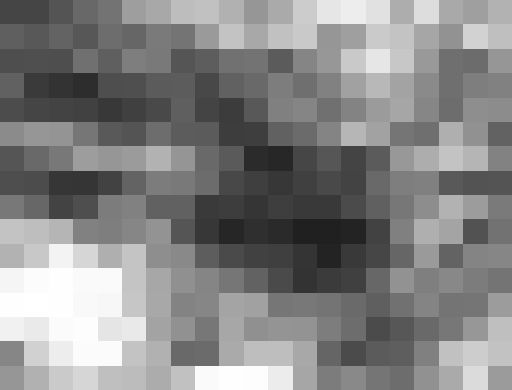

In [5]:
products = recent_clips(
    candidates, CATALOG_DIR, COLLECTION_ID, VIENNA_BBOX, count=SOURCE_COUNT,
)
print([{
    "source_id": product["source"].id,
    "datetime": product["source"].datetime.isoformat(),
} for product in products])
print([{
    "id": product["id"], "actual_bbox": product["bbox"],
    "shape": product["shape"], "valid_pixels": product["valid_pixels"],
    "cog_bytes": product["cog"].stat().st_size,
} for product in products])
display(Image(filename=str(products[1]["directory"] / "preview.png")))

## 4. Describe the clips with Portolan

Portolan creates the STAC tree and GeoParquet table. The helper adds source times, attribution, processing details, and checksums. It checks that the metadata describes the clipped grid and corrects the transform order emitted by the installed Portolan package.

Set the initial asset links to `s3://<workspace>/published/<dataset>/...`. These are private storage locations. There are no PackageR public links at this stage. PackageR lists buckets at its root, so the private browser link includes the workspace bucket: `/files/<workspace>/published/<dataset>/`. Sign in with a workspace account to open it.

In [6]:
collection_path = prepare_catalog(CATALOG_DIR, COLLECTION_ID, products, source_collection)

import hashlib
content_id = hashlib.sha256("".join(
    sha256(path) for product in products
    for path in sorted(product["directory"].iterdir()) if path.is_file()
).encode()).hexdigest()[:12]
DATASET = f"vienna-cloud-fraction-{content_id}"
PUBLISHED_PREFIX = f"published/{DATASET}"
PUBLIC_PREFIX = f"public/{DATASET}"
published_items, published_files = publication_items(
    CATALOG_DIR, products, WORKSPACE_NAME, PUBLISHED_PREFIX,
)
PUBLISHED_INDEX = collection_path.parent / "items.parquet"
PUBLISHED_INDEX_KEY = f"{PUBLISHED_PREFIX}/{COLLECTION_ID}/items.parquet"
check_items(read_parquet(PUBLISHED_INDEX), published_items)
print({"items": len(published_items), "published_prefix": PUBLISHED_PREFIX,
       "first_asset": next(iter(published_items[0].assets.values())).href})

published_browser_url = f"{DATA_URL}/files/{quote(WORKSPACE_NAME, safe='')}/{quote(PUBLISHED_PREFIX, safe='/')}/"
display(HTML(
    f'<p><a href="{escape(published_browser_url, quote=True)}" target="_blank" rel="noopener">'
    'Open the published folder in PackageR</a> (workspace sign-in required; files appear after step 5).</p>'
))


{'items': 3, 'published_prefix': 'published/vienna-cloud-fraction-415580b57482', 'first_asset': 's3://ws-alice/published/vienna-cloud-fraction-415580b57482/vienna-cloud-fraction/vienna-cloud-fraction-20261025/cf.tif'}


## 5. Upload under published/

Portolan uploads the catalogue tree and assets directly to backing S3. The read-only Data S3 endpoint is not used for uploads. Compare the uploaded asset and metadata bytes with the local files.

The publisher stays in kernel memory until relocation finishes. Do not display its storage settings.

In [7]:
publisher = WorkspacePublisher(
    config["OIDC_ISSUER"], config["WORKSPACE_API_ENDPOINT"], WORKSPACE_NAME,
    CLIENT_ID, CLIENT_SECRET,
)
del CLIENT_SECRET
publisher.push(CATALOG_DIR, PUBLISHED_PREFIX)
publisher.verify_assets(published_files)
publisher.verify_assets({PUBLISHED_INDEX_KEY: PUBLISHED_INDEX})
print({"portolan_target": f"s3://{WORKSPACE_NAME}/{PUBLISHED_PREFIX}",
       "published_assets_and_table_verified": True})

display(HTML(
    f'<p><a href="{escape(published_browser_url, quote=True)}" target="_blank" rel="noopener">'
    'Open the uploaded files in PackageR</a> (workspace sign-in required).</p>'
))


{'portolan_target': 's3://ws-alice/published/vienna-cloud-fraction-415580b57482', 'published_assets_and_table_verified': True}


## 6. Deploy the first API and demonstrate search

The first API's startup script downloads the private published item table with storage credentials from a Kubernetes Secret and checks its SHA-256. The API then reads the local table. Its asset links still point to `published/` in S3; a browser cannot download those private assets without storage access.

Apply only the first API manifests. Start a port-forward and check Collection, Item, GET/POST search, spatial filters, and time filters.

If you run the port-forward in your workspace Datalab session, you can access the first API at `/proxy/8000/` on that session's address.

In [8]:
private_secret = {
    "apiVersion": "v1", "kind": "Secret",
    "metadata": {"name": "cng-stac-direct-storage", "labels": {"app": "cng-stac-direct"}},
    "type": "Opaque", "stringData": publisher.api_storage_settings(),
}
direct_values = {
    "INDEX_SHA256": sha256(PUBLISHED_INDEX),
    "INDEX_HREF": f"s3://{WORKSPACE_NAME}/{PUBLISHED_INDEX_KEY}",
    "INDEX_LOADER_SCRIPT": index_loader_code(),
    "REMOTE_COLLECTIONS_JSON": json.dumps([api_collection(collection_path, "/data/items.parquet")]),
    "DIRECT_ROOT_PATH": f"/proxy/{DIRECT_PORT}",
    "STORAGE_ENV_FROM": [{"secretRef": {"name": "cng-stac-direct-storage"}}],
}
try:
    deploy_api(MANIFEST_DIR, DIRECT_MANIFESTS, direct_values, "cng-stac-direct", [private_secret])
finally:
    private_secret["stringData"].clear()
    del private_secret

direct_forward, direct_root = forward_api(
    "cng-stac-direct", DIRECT_PORT, globals().get("direct_forward"),
)
published_features = check_api(direct_root, COLLECTION_ID, published_items, VIENNA_BBOX)
assert all(asset["href"].startswith(f"s3://{WORKSPACE_NAME}/published/")
           for feature in published_features for asset in feature["assets"].values())
print({"stage": "published", "items": len(published_features), "search_checks_passed": True})


{'stage': 'published', 'items': 3, 'search_checks_passed': True}


## 7. Relocate the assets under public/ with stacpkg

Flow 2 uses the assets and metadata uploaded in flow 1. Build a source asset lock from the published Items and an explicit destination lock with the same paths under `public/`. Run `stacpkg asset-lock relocate --destination-lock ... --no-overwrite` with the backing S3 endpoint and credentials fetched through the Workspace API.

This copies the raster, preview, and thumbnail bytes from `published/` to `public/` in the same workspace bucket. It keeps the source objects. Matching destination objects are checked and reused; different content stops the run.

Use the destination lock to set each primary asset `href` to PackageR's permanent HTTP download route. Keep the public S3 location as `alternate.s3.href`. The helper builds the PackageR URL convention; relocation itself does not know that convention. No credentials or expiring signed URLs are stored in metadata.

In [9]:
destination_lock = publisher.relocate(
    published_items, PUBLISHED_PREFIX, PUBLIC_PREFIX, WORK_DIR,
)
items = relocated_items(published_items, destination_lock, DATA_URL)
public_files = {
    key.replace(PUBLISHED_PREFIX + "/", PUBLIC_PREFIX + "/", 1): local
    for key, local in published_files.items()
}
publisher.verify_assets(public_files)
# The original published copy must still match after relocation.
publisher.verify_assets(published_files)
INDEX_PATH = WORK_DIR / "public-items.parquet"
INDEX_KEY = f"{PUBLIC_PREFIX}/{COLLECTION_ID}/items.parquet"
write_parquet(items, INDEX_PATH)
check_items(read_parquet(INDEX_PATH), items)
publisher.upload_metadata(INDEX_PATH, INDEX_KEY)
publisher.verify_assets({INDEX_KEY: INDEX_PATH})
catalogue_items = package_r_items(items, destination_lock)
public_catalog = publisher.update_public_catalog(catalogue_items, WORK_DIR)
publisher.verify_assets({"public/catalog.parquet": public_catalog})
REMOTE_INDEX = public_url(DATA_URL, INDEX_KEY)
print({"relocated_assets": len(destination_lock), "public_prefix": PUBLIC_PREFIX,
       "asset": next(iter(items[0].assets.values())).to_dict(),
       "published_copy_preserved": True})

public_browser_url = (
    f"{DATA_URL}/share/public/"
    f"{quote(PUBLIC_PREFIX.removeprefix('public/') + '/' + COLLECTION_ID, safe='/')}/"
)
display(HTML(
    f'<p><a href="{escape(public_browser_url, quote=True)}" target="_blank" rel="noopener">'
    'Open the relocated files in PackageR</a> (public read access).</p>'
    f'<iframe src="{escape(public_browser_url, quote=True)}" width="100%" height="560" '
    'title="Relocated files in PackageR" loading="lazy"></iframe>'
))


{'relocated_assets': 12, 'public_prefix': 'public/vienna-cloud-fraction-415580b57482', 'asset': {'href': 'https://ws-alice.lab.develop-v2.eoepca.org/api/public/share/public/vienna-cloud-fraction-415580b57482/vienna-cloud-fraction/vienna-cloud-fraction-20261025/cf.tif?presign=true&followRedirect=true', 'type': 'image/tiff; application=geotiff; profile=cloud-optimized', 'title': 'Radiometric cloud fraction', 'file:size': 2179, 'file:checksum': '1220571521de9886f9c21777adbceed982721224da84485613431861f5a2d9664b92', 'render:colormap_name': 'viridis', 'bands': [{'name': 'band_1', 'data_type': 'float32', 'nodata': 9.969209968386869e+36, 'statistics': {'minimum': 0.6207563281059265, 'maximum': 1.0, 'mean': 0.9578314281645275, 'stddev': 0.06768841899197647}, 'unit': '1'}], 'alternate': {'s3': {'href': 's3://ws-alice/public/vienna-cloud-fraction-415580b57482/vienna-cloud-fraction/vienna-cloud-fraction-20261025/cf.tif'}}, 'roles': ['data']}, 'published_copy_preserved': True}


The captured example below shows the relocated item table and scene folders. The link and live view above use the workspace and dataset from this run.

![Relocated item table and three scene folders in PackageR](../img/register-stac-metadata/relocated-files.png)


## 8. Serve the relocated metadata through the first API

Restart the first API with the public item-table URL. Its startup script checks the downloaded table again. This stage needs no storage credentials. Remove the startup storage Secret after the new Pod is ready.

Query the API through the port-forward and download its HTTP assets without workspace login. Check the downloaded bytes and byte-range reads.

If you run the port-forward in your workspace Datalab session, you can access the first API at `/proxy/8000/` on that session's address.

In [10]:
direct_values.update({
    "INDEX_SHA256": sha256(INDEX_PATH), "INDEX_HREF": REMOTE_INDEX,
    "STORAGE_ENV_FROM": [],
})
deploy_api(MANIFEST_DIR, DIRECT_MANIFESTS, direct_values, "cng-stac-direct")
run(["kubectl", "delete", "secret", "cng-stac-direct-storage", "--ignore-not-found"])
publisher.close()
direct_forward, direct_root = forward_api("cng-stac-direct", DIRECT_PORT, direct_forward)
direct_features = check_api(direct_root, COLLECTION_ID, items, VIENNA_BBOX)
assert all(asset["href"].startswith(f"{DATA_URL}/api/public/share/public/")
           for feature in direct_features for asset in feature["assets"].values())
check_public_assets(direct_features)
print({"stage": "public", "search_and_http_assets_verified": True})


secret "cng-stac-direct-storage" deleted from default namespace


{'stage': 'public', 'search_and_http_assets_verified': True}


## 9. Preview with PackageR and MoreGeo STAC Browser

PackageR reads the shared `public/catalog.parquet` table and serves Collection and Item links through the permanent Data service. It has no `/search` route. Its backing table uses share-relative asset paths; PackageR returns HTTP links. The first API above demonstrates search; MoreGeo uses PackageR's public catalogue for this preview.

The public catalogue and HTTP assets must allow cross-origin requests from `https://browser.moregeo.it`. The MoreGeo page runs in your browser and cannot reach a port-forward inside Datalab. If an embedded page is blocked, open the separate link.

In [11]:
downloads = requests.Session()
downloads.trust_env = False
BROWSER_ORIGIN = "https://browser.moregeo.it"
package_r_root = f"{DATA_URL}/api/public/catalog/public"
response = downloads.get(package_r_root, headers={"Origin": BROWSER_ORIGIN}, timeout=60)
response.raise_for_status()
require_browser_cors(response, BROWSER_ORIGIN)
assert response.json()["type"] == "Collection"
package_r_items_url = f"{package_r_root}/{DATASET}/{COLLECTION_ID}"
response = downloads.get(package_r_items_url, headers={"Origin": BROWSER_ORIGIN}, timeout=60)
response.raise_for_status()
require_browser_cors(response, BROWSER_ORIGIN)
package_r_document = response.json()
package_r_features = (
    [package_r_document] if package_r_document["type"] == "Feature"
    else package_r_document["features"]
)
assert {feature["id"] for feature in package_r_features} == {item.id for item in items}
check_items(package_r_features, items)
check_public_assets(package_r_features, origin=BROWSER_ORIGIN)
browser_url = f"https://browser.moregeo.it/external/{package_r_root.removeprefix('https://')}"
display(Markdown(f"[Open the public catalogue]({package_r_root}) · [Open MoreGeo STAC Browser]({browser_url})"))
display(IFrame(src=browser_url, width="100%", height=760))


[Open the public catalogue](https://ws-alice.lab.develop-v2.eoepca.org/api/public/catalog/public) · [Open MoreGeo STAC Browser](https://browser.moregeo.it/external/ws-alice.lab.develop-v2.eoepca.org/api/public/catalog/public)

## 10. Build and publish the OCI package

Package the relocated public item table, an asset lock, and `collections.json`. The image bytes stay in workspace storage. The package uses the same PackageR HTTP asset links checked above.

Enter the session's registry settings if they are not supplied by Datalab. Push the package, resolve the tag to a digest, pull by that digest, and compare every package file.
This starts flow 3. Use the public item table and Collection metadata created in flow 2; no image bytes are included in the package.


In [12]:
local_hashes = build_package(INDEX_PATH, collection_path, PACKAGE_DIR)
REGISTRY_HOST = os.getenv("REGISTRY_HOST") or input("Registry host (without https://): ").strip()
REGISTRY_USERNAME = os.getenv("REGISTRY_USERNAME") or input("Registry username: ").strip()
REGISTRY_PASSWORD = os.getenv("REGISTRY_PASSWORD") or getpass("Registry password: ")
OCI_REPOSITORY = "cng-resource-registration/vienna-cloud-fraction"
oci_reference = transfer_oci(
    PACKAGE_DIR, PULLED_DIR, REGISTRY_HOST, OCI_REPOSITORY,
    REGISTRY_USERNAME, REGISTRY_PASSWORD,
)
assert package_hashes(PULLED_DIR) == local_hashes
print({"oci_reference": oci_reference, "package_sha256": local_hashes,
       "registry_round_trip_verified": True})

{'oci_reference': 'registry-ws-alice-default.lab.develop-v2.eoepca.org/cng-resource-registration/vienna-cloud-fraction@sha256:91d91a711ddd884dc6ee9c2294f4323557cf44df0a68a42cde692cd77c52fa5b', 'package_sha256': {'assets.lock.parquet': '53003296fe43eb7feed41c71521b81ca8619109a3b97d90bea3a8e726f779c0c', 'collections.json': '56ab68cc0cccf2d59fc40c47cca62683c17e79b4febc18b3c7206ab68e1a8a3d', 'items.parquet': '63fa6b09e38f77a42003dab4745662d4069408dce61a3d0c0aca53a0ff425ba5'}, 'registry_round_trip_verified': True}


## 11. Start a second API with an OCI init container

Deploy the OCI API separately. Its init container uses the registry Secret to pull the package by digest into a shared volume. The API reads the local files and needs no storage or registry credentials.

Compare the deployed files with the local package, start a second port-forward, and repeat the search and public asset checks.

If you run the port-forward in your workspace Datalab session, you can access the OCI API at `/proxy/8001/` on that session's address.

| API | Notebook port | Metadata source |
| --- | --- | --- |
| First API | 8000 | Published S3 table first, then public HTTP table. |
| OCI API | 8001 | Local metadata pulled by digest by its init container. |

In [13]:
oci_values = {
    "REGISTRY_HOST": REGISTRY_HOST, "REGISTRY_USERNAME": REGISTRY_USERNAME,
    "REGISTRY_PASSWORD": REGISTRY_PASSWORD, "OCI_REFERENCE": oci_reference,
    "OCI_PULL_SCRIPT": registry_client_code() + """
import os
import stacpkg.oci as registry

use_registry_credentials(os.environ["REGISTRY_USERNAME"], os.environ["REGISTRY_PASSWORD"])
registry.pull_package(os.environ["OCI_REFERENCE"], "/data/package", auth_backend="basic")
""",
    "OCI_ROOT_PATH": f"/proxy/{OCI_PORT}",
}
try:
    deploy_api(MANIFEST_DIR, OCI_MANIFESTS, oci_values, "cng-stac-api")
finally:
    oci_values.clear()
    REGISTRY_PASSWORD = None

staged_result = run([
    "kubectl", "exec", "deployment/cng-stac-api", "-c", "api", "--", "python", "-c",
    "import hashlib,json; from pathlib import Path; "
    "print(json.dumps({p.name:hashlib.sha256(p.read_bytes()).hexdigest() "
    "for p in Path('/data/package').iterdir() if p.is_file() and p.name!='manifest.json'}))",
])
assert json.loads(staged_result.stdout) == local_hashes
oci_forward, oci_root = forward_api("cng-stac-api", OCI_PORT, globals().get("oci_forward"))
oci_features = check_api(oci_root, COLLECTION_ID, items, VIENNA_BBOX)
check_public_assets(oci_features)
assert {feature["id"] for feature in direct_features} == {feature["id"] for feature in oci_features}
print({"deployed_package_verified": True, "both_apis_and_public_assets_verified": True})


{"items.parquet": "63fa6b09e38f77a42003dab4745662d4069408dce61a3d0c0aca53a0ff425ba5", "collections.json": "56ab68cc0cccf2d59fc40c47cca62683c17e79b4febc18b3c7206ab68e1a8a3d", "assets.lock.parquet": "53003296fe43eb7feed41c71521b81ca8619109a3b97d90bea3a8e726f779c0c"}


{'deployed_package_verified': True, 'both_apis_and_public_assets_verified': True}


## 12. Keep or remove the APIs

The APIs stay available by default. Port-forwards last while the kernel is running. Set `CLEAN_UP = True` to remove the two API workloads, Services, ConfigMaps, and Secrets.

The `published/` source files, `public/` copies, shared catalogue, and OCI package stay in the workspace.

In [14]:
CLEAN_UP = False
if CLEAN_UP:
    for process in (direct_forward, oci_forward):
        if process.poll() is None:
            process.terminate()
            process.wait(timeout=10)
    for label in ("app=cng-stac-direct", "app=cng-stac-api"):
        run(["kubectl", "delete", "deployment,service,configmap,secret",
             "-l", label, "--ignore-not-found"])
else:
    print("The two APIs and both storage copies are kept for inspection.")


The two APIs and both storage copies are kept for inspection.


## Result

Portolan publishes the clipped rasters and metadata under `published/`. The first API demonstrates search over those Items. stacpkg relocation then copies the assets under `public/` in the same workspace bucket. The updated metadata uses PackageR HTTP asset links for downloads and the MoreGeo preview.

The final scenario pushes the public metadata package to the workspace OCI container registry as an artifact. A second API loads it by digest through an init container, so a team can deploy the same catalogue again. The checks compare the source and destination asset bytes, metadata grids, search results, package files, and deployed OCI files.